In [1]:
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("Environment:", sys.executable)
print("OpenCV:", cv2.__version__)

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Environment: c:\Users\arshi\Desktop\vision_inspection\.venv\Scripts\python.exe
OpenCV: 5.0.0


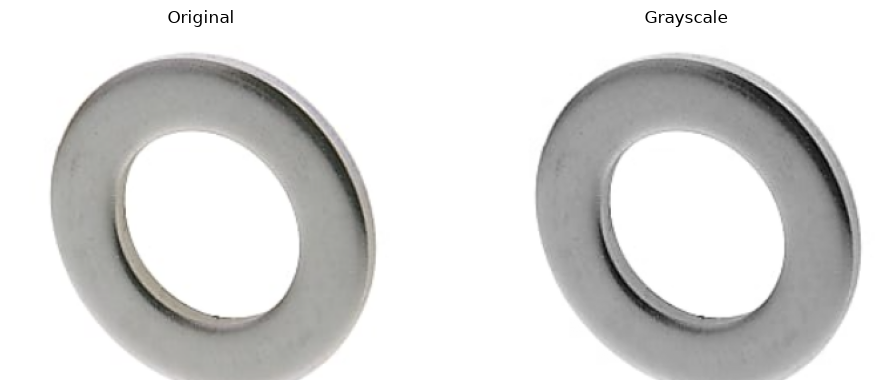

In [2]:
from pathlib import Path

image_path = Path("sample.png")
image = cv2.imread(str(image_path))

if image is None:
    print("Image not found or unreadable:", image_path.resolve())
else:
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(rgb)
    axes[0].set_title("Original")

    axes[1].imshow(gray, cmap="gray")
    axes[1].set_title("Grayscale")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

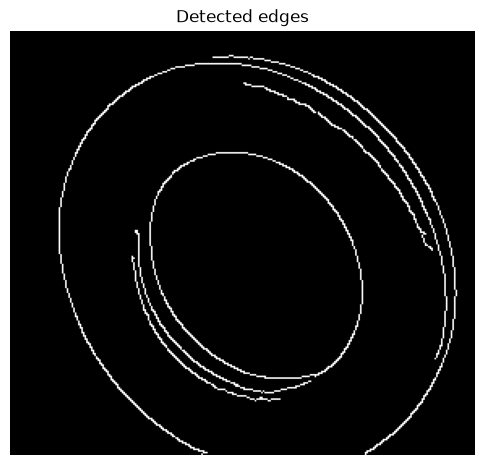

In [3]:
# Reduce image noise before finding edges
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Find boundaries where brightness changes sharply
edges = cv2.Canny(blurred, 50, 150)

plt.figure(figsize=(6, 6))
plt.imshow(edges, cmap="gray")
plt.title("Detected edges")
plt.axis("off")
plt.show()

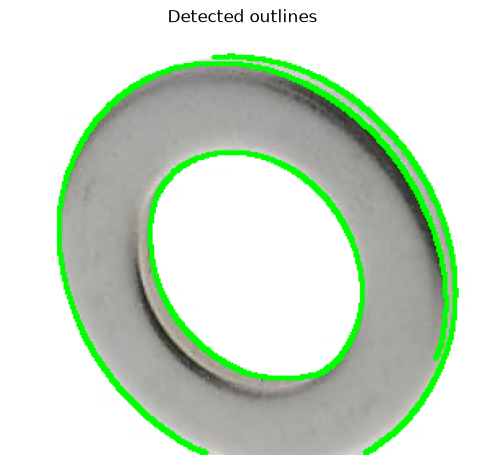

In [4]:
contours, _ = cv2.findContours(
    edges,
    cv2.RETR_LIST,
    cv2.CHAIN_APPROX_SIMPLE
)

# Ignore very small outlines caused by noise
filtered_contours = [
    contour for contour in contours
    if cv2.contourArea(contour) > 100
]

outlined = rgb.copy()

cv2.drawContours(
    outlined,
    filtered_contours,
    -1,
    (0, 255, 0),
    2
)

plt.figure(figsize=(6, 6))
plt.imshow(outlined)
plt.title("Detected outlines")
plt.axis("off")
plt.show()

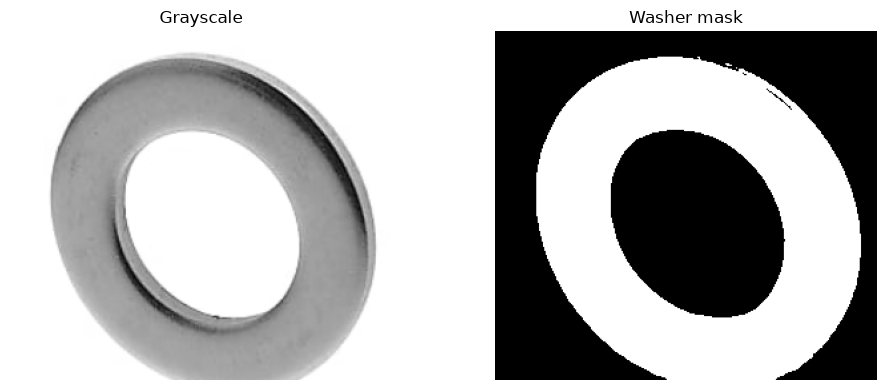

Selected threshold: 206.0


In [5]:
# Smooth small brightness variations
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Automatically choose a threshold:
# darker washer becomes white, lighter background becomes black
threshold, mask = cv2.threshold(
    blurred,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Grayscale")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Washer mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Selected threshold:", round(threshold, 1))

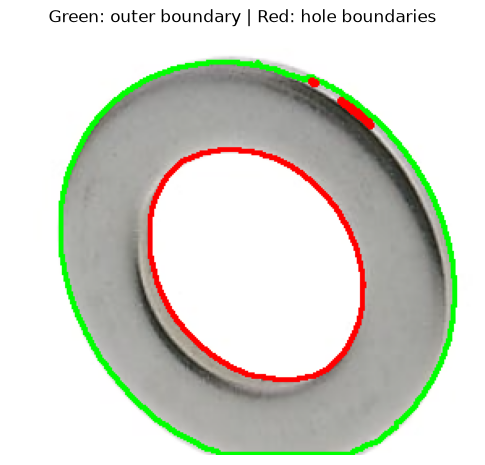

Detected hole candidates: 14


In [6]:
contours, hierarchy = cv2.findContours(
    mask,
    cv2.RETR_CCOMP,
    cv2.CHAIN_APPROX_SIMPLE
)

result = rgb.copy()

if hierarchy is None:
    print("No outlines found. Check the binary mask.")
else:
    hierarchy = hierarchy[0]

    # Find contours that have no parent (outer boundaries)
    outer_indices = [
        i for i, info in enumerate(hierarchy)
        if info[3] == -1
    ]

    # Assume the largest foreground object is the washer
    outer_index = max(
        outer_indices,
        key=lambda i: cv2.contourArea(contours[i])
    )

    # Find holes belonging to that object
    hole_indices = [
        i for i, info in enumerate(hierarchy)
        if info[3] == outer_index
    ]

    cv2.drawContours(result, contours, outer_index, (0, 255, 0), 2)

    for i in hole_indices:
        cv2.drawContours(result, contours, i, (255, 0, 0), 2)

    plt.figure(figsize=(6, 6))
    plt.imshow(result)
    plt.title("Green: outer boundary | Red: hole boundaries")
    plt.axis("off")
    plt.show()

    print("Detected hole candidates:", len(hole_indices))

In [7]:
if hierarchy is None:
    print("Run the previous cell and check that contours were found.")
elif not hole_indices:
    print("No enclosed hole detected. Check the mask.")
else:
    # Treat the largest enclosed region as the centre hole
    hole_index = max(
        hole_indices,
        key=lambda i: cv2.contourArea(contours[i])
    )

    outer_area = cv2.contourArea(contours[outer_index])
    hole_area = cv2.contourArea(contours[hole_index])

    if outer_area > 0:
        hole_ratio = hole_area / outer_area

        print(f"Area inside outer boundary: {outer_area:.1f} pixels²")
        print(f"Centre-hole area: {hole_area:.1f} pixels²")
        print(f"Hole-to-outer-area ratio: {hole_ratio:.3f}")
        print(f"Hole occupies {hole_ratio * 100:.1f}% of the outer area.")
    else:
        print("Outer contour has zero area. Check the mask.")

Area inside outer boundary: 46739.5 pixels²
Centre-hole area: 14434.0 pixels²
Hole-to-outer-area ratio: 0.309
Hole occupies 30.9% of the outer area.


Outer boundary:
  Long axis:  264.4 pixels
  Short axis: 226.5 pixels
Centre hole:
  Long axis:  154.2 pixels
  Short axis: 119.4 pixels


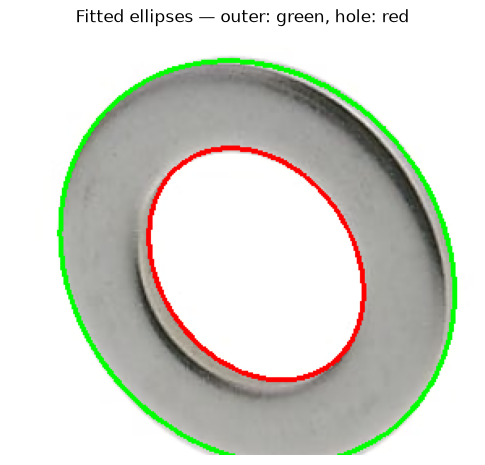

In [8]:
if hierarchy is None or not hole_indices:
    print("An outer boundary and a hole are required.")
else:
    hole_index = max(
        hole_indices,
        key=lambda i: cv2.contourArea(contours[i])
    )

    result = rgb.copy()

    for label, index, color in [
        ("Outer boundary", outer_index, (0, 255, 0)),
        ("Centre hole", hole_index, (255, 0, 0))
    ]:
        contour = contours[index]

        if len(contour) < 5:
            print(f"{label}: too few points to fit an ellipse.")
            continue

        ellipse = cv2.fitEllipse(contour)
        centre, axes, angle = ellipse

        short_axis, long_axis = sorted(axes)

        cv2.ellipse(result, ellipse, color, 2)

        print(f"{label}:")
        print(f"  Long axis:  {long_axis:.1f} pixels")
        print(f"  Short axis: {short_axis:.1f} pixels")

    plt.figure(figsize=(6, 6))
    plt.imshow(result)
    plt.title("Fitted ellipses — outer: green, hole: red")
    plt.axis("off")
    plt.show()

In [9]:
if hierarchy is None:
    print("No outer boundary available. Run the contour cell first.")
else:
    outer_contour = contours[outer_index]

    height, width = mask.shape
    points = outer_contour.reshape(-1, 2)

    # Flag contours within 2 pixels of an image edge
    margin = 2

    touches_border = (
        (points[:, 0] <= margin).any()
        or (points[:, 0] >= width - 1 - margin).any()
        or (points[:, 1] <= margin).any()
        or (points[:, 1] >= height - 1 - margin).any()
    )

    if touches_border:
        inspection_status = "REVIEW: part may be cropped"
    elif not hole_indices:
        inspection_status = "REVIEW: centre hole not detected"
    else:
        inspection_status = "READY for further measurement checks"

    print("Inspection status:", inspection_status)

Inspection status: REVIEW: part may be cropped


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.tensor([1.0, 2.0, 3.0], device="cuda")
    print("GPU calculation:", (x * 2).cpu().tolist())
else:
    print("PyTorch cannot access the GPU yet.")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU calculation: [2.0, 4.0, 6.0]


In [2]:
from importlib.metadata import version
import torch
from anomalib.models import EfficientAd
from anomalib.engine import Engine

print("Anomalib:", version("anomalib"))
print("CUDA available:", torch.cuda.is_available())
print("Model tools imported successfully")

W0919 09:03:28.699000 7844 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Anomalib: 2.6.2
CUDA available: True
Model tools imported successfully


c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\anomalib\models\image\dinomaly\components\layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


Normal training images: 220
Test images: 115
Defect masks: 93


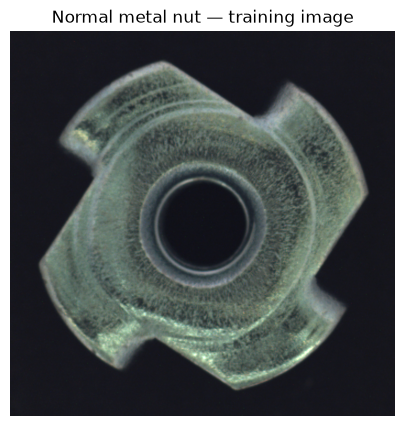

In [3]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

dataset_path = Path("datasets/MVTecAD/metal_nut")

train_images = sorted(
    (dataset_path / "train" / "good").glob("*.png")
)
test_images = sorted(
    (dataset_path / "test").glob("*/*.png")
)
defect_masks = sorted(
    (dataset_path / "ground_truth").glob("*/*.png")
)

print("Normal training images:", len(train_images))
print("Test images:", len(test_images))
print("Defect masks:", len(defect_masks))

if train_images:
    image = Image.open(train_images[0]).convert("RGB")

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title("Normal metal nut — training image")
    plt.axis("off")
    plt.show()
else:
    print("No training images found. Check this folder:")
    print(dataset_path.resolve())

In [1]:
from anomalib.data import MVTecAD

datamodule = MVTecAD(
    root="datasets/MVTecAD",
    category="metal_nut",
    train_batch_size=1,
    eval_batch_size=8,
    num_workers=0,
    val_split_mode="from_test",
    val_split_ratio=0.5,
    seed=42,
)

datamodule.setup()

print("Training images:", len(datamodule.train_data))
print("Validation images:", len(datamodule.val_data))
print("Test images:", len(datamodule.test_data))

# Verify that validation and final test images are separate
val_paths = set(datamodule.val_data.samples["image_path"])
test_paths = set(datamodule.test_data.samples["image_path"])

assert val_paths.isdisjoint(test_paths)
print("Validation and test sets do not overlap.")

W0919 09:45:46.988000 6236 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Training images: 220
Validation images: 57
Test images: 58
Validation and test sets do not overlap.


c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import torch
from lightning.pytorch import seed_everything
from anomalib.models import EfficientAd
from anomalib.engine import Engine

assert torch.cuda.is_available(), "GPU is unavailable."
assert len(datamodule.train_data) > 0, "Training data is empty."

seed_everything(42, workers=True)

model = EfficientAd(
    pre_processor=EfficientAd.configure_pre_processor(
        image_size=(256, 256)
    ),
)

engine = Engine(
    accelerator="gpu",
    devices=1,
    max_epochs=1,
    num_sanity_val_steps=0,
    default_root_dir="results/efficientad_trial",
    logger=False,
    enable_progress_bar=False,
)

print("Starting training...")
engine.fit(model=model, datamodule=datamodule)
print("One-epoch training trial completed.")

c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\anomalib\models\image\dinomaly\components\layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention
Seed set to 42
c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'pre_processor' is an instance of `nn.Module` and is already saved during checkpointing. It is recommende

Starting training...


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor     │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor    │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator        │      0 │ train │     0 │
│ 3 │ model          │ EfficientAdModel │  8.1 M │ train │     0 │
└───┴────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 8.1 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 8.1 M                                                                                                
Total estimated model params size (MB): 32.235                                                                     
Modules in train mode: 48                                                                                          
Modules in eval mode: 7                                                                                            
Total FLOPs: 0

c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\lightning\pytorch\loops\fit_loop.py:538: Found 7 module(s)

One-epoch training trial completed.


In [3]:
print("Validation results:")

for name, value in engine.trainer.callback_metrics.items():
    if hasattr(value, "numel") and value.numel() == 1:
        print(f"{name}: {value.item():.4f}")
    else:
        print(f"{name}: {value}")

print(
    "\nSaved checkpoint:",
    engine.trainer.checkpoint_callback.best_model_path
)

Validation results:
train_st: 13.5203
train_st_step: 10.3393
train_ae: 0.9297
train_ae_step: 0.8744
train_stae: 0.0201
train_stae_step: 0.0277
train_loss: 14.4701
train_loss_step: 11.2414
train_st_epoch: 13.5203
train_ae_epoch: 0.9297
train_stae_epoch: 0.0201
train_loss_epoch: 14.4701

Saved checkpoint: C:\Users\arshi\Desktop\vision_inspection\results\efficientad_trial\EfficientAd\MVTecAD\metal_nut\v1\weights\lightning\model.ckpt


In [4]:
validation_results = engine.test(
    model=model,
    dataloaders=datamodule.val_dataloader(),
)

print(validation_results)

The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\arshi\Desktop\vision_inspection\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│        image_AUROC        │    0.4940711557865143     │
│       image_F1Score       │    0.8823529481887817     │
│        pixel_AUROC        │    0.8110379576683044     │
│       pixel_F1Score       │    0.4352641701698303     │
└───────────────────────────┴───────────────────────────┘

[{'image_AUROC': 0.4940711557865143, 'image_F1Score': 0.8823529481887817, 'pixel_AUROC': 0.8110379576683044, 'pixel_F1Score': 0.4352641701698303}]


In [5]:
samples = datamodule.val_data.samples

print("Validation image counts:")
print(
    samples["label_index"]
    .value_counts()
    .rename(index={0: "Normal", 1: "Defective"})
)

Validation image counts:
label_index
Defective    46
Normal       11
Name: count, dtype: int64
